<a href="https://colab.research.google.com/github/angvtb/Hands-on-Exploratory-Data-Analysis-with-Python/blob/master/notebooks/Proyecto-aplicado-Desa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Proyecto aplicado 1

Luis Felipe Rangel
Daniel Alarcón
Edward Atehortua
Angie Tamara
Frank Mendoza


# Clasificación automática de etiquetas industriales para la prevención de crosspacking

**Proyecto aplicado · Maestría en Ciencia de Datos · Universidad Icesi**
**Empresa aliada: MV Perception**

Luis Felipe Rangel · Daniel Alarcón · Edward Atehortua · Angie Tamara · Frank Mendoza

---

## El problema

En la línea de envasado se produce *crosspacking*: un producto sale con la etiqueta de una
referencia distinta a la que indica la orden de producción. La línea procesa 250 unidades por
minuto, es decir una cada 240 milisegundos, alterna 43 referencias y opera de forma continua.

Este cuaderno desarrolla y evalúa un modelo de clasificación de imágenes que identifica la
referencia a partir de su etiqueta, para contrastarla con la orden de producción.

## Las metas que fija la empresa

| Meta | Valor | Cómo se verifica en este cuaderno |
|---|---|---|
| Precisión | superior al 95 % | Sección 4, con el protocolo de partición declarado en la sección 2 |
| Tiempo de inferencia | inferior a 240 ms | Sección 5, percentil 95 sobre la cadena completa |

## Estructura del cuaderno

| Sección | Contenido |
|---|---|
| 0 | Configuración: librerías, conexión con Drive y parámetros |
| 1 | Comprensión de los datos: inventario, integridad, duplicados, procedencia y distribución |
| 2 | Preparación: depuración, protocolo de partición y preprocesamiento |
| 3 | Modelado: línea base clásica, red propia y tres arquitecturas con transferencia |
| 4 | Evaluación: métricas globales, por clase y sobre los pares difíciles |
| 5 | Latencia: medición de la cadena completa contra el presupuesto de la línea |
| 6 | Comparativo entre modelos y conclusiones |

## Cómo reproducirlo

Las imágenes no están en el repositorio: pesan unos 10 GB y viven en Google Drive.
La sección 0 monta Drive y verifica que el conjunto esté completo antes de ejecutar nada más.

Las operaciones costosas guardan su resultado en caché dentro de `pa1-analisis`, de modo que
una interrupción de Colab no obliga a repetirlas. Las particiones y las semillas quedan fijadas
en la sección 0, así que dos ejecuciones distintas producen los mismos subconjuntos y los
mismos resultados.

**Nota sobre la partición.** Las imágenes de una misma secuencia de disparos no son
observaciones independientes. Repartirlas al azar entre entrenamiento y prueba infla el
resultado: la sección 1 lo mide sobre este mismo conjunto. El protocolo de partición que usa
este cuaderno se define y se justifica en la sección 2.

## Pendientes

Actualizado: 20 de octubre de 2026. Cuando un punto se resuelva, se anota la
decisión en su fila y se pasa a la tabla de resueltos.

| # | Pendiente | De qué depende | Dónde se resuelve |
|---|---|---|---|
| 1 | Si la hora del nombre del archivo es la de captura o la de guardado | Respuesta de la empresa (pregunta 1) | Sección 2: define si la partición puede bajar de jornada a sesión |
| 2 | Cuatro capturas de 1440×1080 en `30_SEDAL_UV_650` (índices 0010 a 0013, 27 jun 2025): descartar o recortar | Respuesta de la empresa (pregunta 4) | Sección 2, preparación |
| 3 | Enderezar `Image_2789_20250204163945.bmp` de `27_SEDAL_KERATINA_650` | Nada; ya está decidido | Sección 2, preparación |
| 4 | Cuál de las dos sesiones de julio de `21_SEDAL_RIZOS_DEFINIDOS_340` es la real | Respuesta de la empresa (pregunta 3). Para la partición basta con que vayan juntas | Sección 2, partición |
| 5 | Carpetas 2 y 10 (Colágeno Savital 510 con dos artes): una clase o dos | Decisión del equipo | Sección 2, definición de clases |
| 6 | Revisión visual de una imagen por clase y jornada, y prueba de OCR sobre el contenido neto | Nada; es trabajo del equipo | Sección 1.9 |
| 7 | Captura de los pares finos (3 y 4, 7 y 11) en una misma sesión | Solicitud a la empresa | Antes de la evaluación final |
| 8 | Registrar en `DECISIONES.md` los nombres corregidos de las carpetas 11 y 28 | Nada | Fuera del cuaderno |

### Resueltos

| Pendiente | Decisión | Fecha |
|---|---|---|
| Duplicados exactos | Se conserva una imagen por huella MD5; se descartan 163 | 20 oct 2026 |
| Imágenes compartidas entre 22 y 28 | Se conservan en la 28 (muestran 650 ml) | 20 oct 2026 |
| Nombre de la carpeta 11 | Clase `11_SERUM_SAVITAL_510` | 20 oct 2026 |
| Nombre de la carpeta 28 | Clase `28_SEDAL_PREBIOTICOS_650` | 20 oct 2026 |
| `123.bmp` sin hora de captura | Se descarta: es un duplicado exacto de `Imagen_0009_20250204204004.bmp` (carpeta 29), que se conserva | 20 oct 2026 |

## 0. Configuración

Librerías, conexión con Google Drive y parámetros del análisis. Las rutas y los umbrales
quedan reunidos en una sola celda: si cambia la ubicación del conjunto o se ajusta un criterio,
se modifica ahí y no en el resto del cuaderno.

In [1]:
import os
import re
import time
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 60)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})

print('numpy', np.__version__, '· pandas', pd.__version__, '· Pillow', Image.__version__)

numpy 2.1.3 · pandas 2.2.3 · Pillow 11.3.0


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# ---------- Rutas. Ajustar si las carpetas tienen otro nombre en Drive ----------
RAIZ   = Path('/content/drive/MyDrive/pa1-imagenes')    # contiene las 43 carpetas de referencias
SALIDA = Path('/content/drive/MyDrive/pa1-analisis')    # caché, tablas y figuras
SALIDA.mkdir(parents=True, exist_ok=True)

# ---------- Reproducibilidad ----------
SEMILLA = 42
np.random.seed(SEMILLA)
rng = np.random.default_rng(SEMILLA)

# ---------- Umbrales del análisis exploratorio ----------
CORTE_SESION = 600     # segundos sin disparos que definen otra jornada de trabajo
CORTE_RAFAGA = 3       # segundos sin disparos que definen otra ráfaga
RMSE_CASI    = 4.0     # error cuadrático medio bajo el cual dos imágenes son casi la misma
LADO_MINI    = 256     # lado largo de la miniatura usada para comparar imágenes

# ---------- Parámetros de la partición ----------
FRAC_PRUEBA = 0.30     # proporción de ráfagas que van a prueba en las clases de una sola jornada
FRAC_VALID  = 0.20     # proporción de ráfagas de entrenamiento que van a validación

# ---------- Características del montaje, usadas para interpretar resoluciones ----------
ANCHO_NATIVO = 1440
ALTO_NATIVO  = 944
MM_POR_PIXEL = 240 / ANCHO_NATIVO   # campo de visión horizontal de 240 mm

print(f'origen : {RAIZ}')
print(f'salida : {SALIDA}')
print(f'escala : {MM_POR_PIXEL:.4f} mm por píxel')

origen : /content/drive/MyDrive/pa1-imagenes
salida : /content/drive/MyDrive/pa1-analisis
escala : 0.1667 mm por píxel


In [5]:
assert RAIZ.exists(), f'No existe la ruta {RAIZ}. Revisa el nombre de la carpeta en Drive.'

carpetas = sorted(
    [d for d in RAIZ.iterdir() if d.is_dir() and not d.name.startswith(('_', '.'))],
    key=lambda d: int(d.name.split('_')[0]) if d.name.split('_')[0].isdigit() else 999
)

conteo = {c.name: len([f for f in os.listdir(c) if f.lower().endswith('.bmp')]) for c in carpetas}
total = sum(conteo.values())

print(f'{len(carpetas)} carpetas · {total} imágenes BMP\n')
for nombre, n in conteo.items():
    print(f'  {nombre:36s} {n:>5}')

ESPERADAS_CARPETAS = 43
ESPERADAS_IMAGENES = 2605
if len(carpetas) != ESPERADAS_CARPETAS or total != ESPERADAS_IMAGENES:
    print(f'\nAVISO: se esperaban {ESPERADAS_CARPETAS} carpetas y {ESPERADAS_IMAGENES} imágenes.')
    print('Si la subida a Drive todavía no termina, conviene esperar antes de continuar.')
else:
    print('\nEl conjunto está completo.')

50 carpetas · 3159 imágenes BMP

  0_MULTIVIAMINAS_SAVITAL_510             37
  1_ANTICASPA_SAVITAL_510                 74
  2_COLAGENO_SAVITAL_510                  64
  3_FUSION_SAVITAL_490                    41
  4_FUSION_SAVITAL_510                   107
  5_HIALURONICO_SAVITAL_510               31
  6_MULTIOLEOS_SAVITAL_510                24
  7_SERUM_SAVITAL_490                     51
  8_ARGAN_SAVITAL_510                     41
  9_ANTICASPA_LIMPIEZA_SAVITAL_510       133
  10_COLAGENO_SAVITAL_510                 35
  11_SERUM_SAVITAL_490                    47
  12_ELIXIR_SAVITAL_510                   19
  13_DOVE_NUTRICION_370                  135
  14_DOVE_RECONSTRUCCION_370              49
  15_DOVE_REGENERACION_370                92
  16_DOVE_REPAIR_350                      87
  17_DOVE_HIDRA_SUAVE_370                111
  18_DOVE_HIDRA_370                       24
  19_SEDAL_UV_340                         52
  20_SEDAL_ZERO_CASPA_340                 95
  21_SEDAL_RIZOS_DEFIN

## 1 Comprensión de los datos

Esta sección reconstruye el inventario del conjunto desde los archivos, verifica su
integridad, identifica duplicados, reconstruye la procedencia temporal de cada imagen y
mide el desbalance entre clases.

Cierra con la medida que más condiciona el resto del cuaderno: cuánto cambia el resultado
según cómo se reparta el conjunto entre entrenamiento y prueba.

### 1.1 Inventario

Una sola pasada sobre las **2.605** imágenes. En ese recorrido se calcula, por archivo:

- el **resumen MD5** del contenido, que identifica archivos idénticos byte a byte;
- la **cabecera del BMP**, que da resolución, modo de color y número de canales;
- la **marca de tiempo** codificada en el nombre, que da la procedencia temporal;
- las **estadísticas fotométricas** por canal, que miden la variación de iluminación;
- una **miniatura en gris**, que permite comparar imágenes entre sí sin volver a leer los 10 GB.

Hacerlo todo en un solo recorrido evita leer el conjunto cinco veces. El resultado queda en
caché, de modo que una desconexión de Colab no obliga a repetir la pasada.

In [11]:
# ── 1.1 Inventario: una sola pasada por el dataset ──
# Lee cada BMP una vez y de esa lectura saca todo lo que se necesita después:
# huella MD5, encabezado, marca de tiempo del nombre, estadística fotométrica
# y una miniatura en gris. Guarda avance por carpeta para poder retomar.
import struct, hashlib
from io import BytesIO

SALIDA = Path('/content/drive/MyDrive/pa1-salidas')   # resultados, fuera del dataset
SALIDA.mkdir(parents=True, exist_ok=True)
assert RAIZ.is_dir(),  f'No existe el dataset en {RAIZ}'
assert SALIDA != RAIZ, 'Las salidas no pueden ir dentro del dataset'
print('Dataset:', RAIZ, '\nSalidas:', SALIDA)

PATRON    = re.compile(r'^Imagen?_(\d+)_(\d{14})', re.IGNORECASE)
RUTA_INV  = SALIDA / 'inventario.csv'
RUTA_MINI = SALIDA / 'miniaturas.npz'
ALTO_MINI = round(LADO_MINI * ALTO_NATIVO / ANCHO_NATIVO)

COLUMNAS = ['carpeta','archivo','ruta','bytes','md5','ancho','alto','alto_crudo',
            'bpp','canales','compresion','offset_datos','tam_cabecera',
            'indice','marca_tiempo','media','desv','p01','p50','p99',
            'frac_oscuros','frac_quemados']

def leer_cabecera(b):
    """Campos del BITMAPFILEHEADER + BITMAPINFOHEADER, o None si no es BMP."""
    if b[:2] != b'BM':
        return None
    offset,  = struct.unpack('<I', b[10:14])
    tam_cab, = struct.unpack('<I', b[14:18])
    ancho, alto = struct.unpack('<ii', b[18:26])
    _planos, bpp = struct.unpack('<HH', b[26:30])
    compresion, = struct.unpack('<I', b[30:34])
    return offset, tam_cab, ancho, alto, bpp, compresion

def medir(ruta_abs, carpeta, archivo):
    datos = ruta_abs.read_bytes()
    cab = leer_cabecera(datos[:54])
    if cab is None:
        offset = tam_cab = ancho = alto = bpp = compresion = -1
    else:
        offset, tam_cab, ancho, alto, bpp, compresion = cab
    g = np.asarray(Image.open(BytesIO(datos)).convert('L'))
    mini = np.asarray(Image.fromarray(g).resize((LADO_MINI, ALTO_MINI)), dtype=np.uint8)
    m = PATRON.match(archivo)
    p01, p50, p99 = np.percentile(g, [1, 50, 99])
    fila = dict(
        carpeta=carpeta, archivo=archivo, ruta=f'{carpeta}/{archivo}',
        bytes=len(datos), md5=hashlib.md5(datos).hexdigest(),
        ancho=ancho, alto=abs(alto), alto_crudo=alto, bpp=bpp,
        canales=max(bpp // 8, 1), compresion=compresion,
        offset_datos=offset, tam_cabecera=tam_cab,
        indice=int(m.group(1)) if m else -1,
        marca_tiempo=m.group(2) if m else '',
        media=round(float(g.mean()), 3), desv=round(float(g.std()), 3),
        p01=float(p01), p50=float(p50), p99=float(p99),
        frac_oscuros=round(float((g <= 5).mean()), 5),
        frac_quemados=round(float((g >= 250).mean()), 5))
    return fila, mini

# --- lo que ya esté calculado se reutiliza ---
hecho_filas, hecho_mini = {}, {}
if RUTA_INV.exists():
    prev = pd.read_csv(RUTA_INV, dtype={'marca_tiempo': str})
    if set(COLUMNAS).issubset(prev.columns):
        prev = prev.drop_duplicates('ruta')
        hecho_filas = {r['ruta']: r for r in prev[COLUMNAS].to_dict('records')}
        if RUTA_MINI.exists():
            z = np.load(RUTA_MINI, allow_pickle=False)
            hecho_mini = dict(zip(z['rutas'].tolist(), z['mini']))
        print(f'Caché: {len(hecho_filas)} filas y {len(hecho_mini)} miniaturas reutilizables.')
    else:
        print('La caché existente tiene otras columnas. Se recalcula desde cero.')
else:
    print('Sin caché previa. Primera pasada completa.')

carpetas = sorted([d for d in RAIZ.iterdir() if d.is_dir()], key=lambda d: d.name)
filas, minis, claves = [], [], []
t0, nuevas = time.time(), 0

for i, carp in enumerate(carpetas, 1):
    archivos = sorted(p.name for p in carp.iterdir() if p.suffix.lower() == '.bmp')
    for nombre in archivos:
        clave = f'{carp.name}/{nombre}'
        if clave in hecho_filas and clave in hecho_mini:
            fila, mini = hecho_filas[clave], hecho_mini[clave]
        else:
            fila, mini = medir(carp / nombre, carp.name, nombre)
            nuevas += 1
        filas.append(fila); minis.append(mini); claves.append(clave)
    try:
        pd.DataFrame(filas)[COLUMNAS].to_csv(RUTA_INV, index=False)
        if i % 10 == 0 or i == len(carpetas):
            np.savez_compressed(RUTA_MINI, mini=np.stack(minis), rutas=np.array(claves))
    except OSError as e:
        print('  aviso: no se guardó el avance de esta carpeta →', e)
    print(f'[{i:2d}/{len(carpetas)}] {carp.name:40s} {len(archivos):4d} img · '
          f'leídas de Drive {nuevas:4d} · {(time.time()-t0)/60:5.1f} min')

inv = pd.DataFrame(filas)[COLUMNAS]
inv['marca_tiempo'] = pd.to_datetime(inv.marca_tiempo, format='%Y%m%d%H%M%S', errors='coerce')
MINI, CLAVES_MINI = np.stack(minis), claves

print(f'\nInventario: {len(inv)} filas · {inv.carpeta.nunique()} carpetas · '
      f'{inv.bytes.sum()/2**30:.2f} GiB · miniaturas {MINI.shape}')
print('Coincide con lo esperado:', len(inv) == ESPERADAS_IMAGENES
      and inv.carpeta.nunique() == ESPERADAS_CARPETAS)

Dataset: /content/drive/MyDrive/pa1-imagenes 
Salidas: /content/drive/MyDrive/pa1-salidas
Caché: 2605 filas y 2605 miniaturas reutilizables.
[ 1/43] 0_MULTIVIAMINAS_SAVITAL_510                37 img · leídas de Drive    0 ·   0.0 min
[ 2/43] 10_COLAGENO_SAVITAL_510                    35 img · leídas de Drive    0 ·   0.0 min
[ 3/43] 11_SERUM_SAVITAL_490                       47 img · leídas de Drive    0 ·   0.0 min
[ 4/43] 12_ELIXIR_SAVITAL_510                      19 img · leídas de Drive    0 ·   0.0 min
[ 5/43] 13_DOVE_NUTRICION_370                     135 img · leídas de Drive    0 ·   0.0 min
[ 6/43] 14_DOVE_RECONSTRUCCION_370                 49 img · leídas de Drive    0 ·   0.0 min
[ 7/43] 15_DOVE_REGENERACION_370                   92 img · leídas de Drive    0 ·   0.0 min
[ 8/43] 16_DOVE_REPAIR_350                         87 img · leídas de Drive    0 ·   0.0 min
[ 9/43] 17_DOVE_HIDRA_SUAVE_370                   111 img · leídas de Drive    0 ·   0.0 min
[10/43] 18_DOVE_HIDRA_

#### Lectura de resultados: inventario

El código abre cada BMP una sola vez y, de esa lectura, calcula su huella MD5, lee el
encabezado, extrae la fecha y hora del nombre, mide la estadística de brillo en gris y
guarda una miniatura de 256×168. Guarda el avance después de cada carpeta, de modo que
una desconexión de Colab no obliga a empezar de nuevo. Se hace todo en un solo
recorrido porque el cuello de botella es la lectura desde Drive, no el cálculo.

El resultado es una tabla de 2.605 filas, una por imagen, de 43 carpetas y unos
9,9 GiB, más un arreglo de 2.605 miniaturas. Las cifras coinciden con el conteo
esperado, y todo el resto del cuaderno trabaja sobre estos dos objetos sin volver a
leer las imágenes originales.

### 1.2 Integridad del formato

El BMP que escribe la cámara no lleva metadatos: el encabezado ocupa 54 bytes
y a partir de ahí todo es píxel. La procedencia de cada imagen se reconstruye
entonces desde dos fuentes, el encabezado y el nombre del archivo
(`Image_NNNN_AAAAMMDDhhmmss`), y conviene confirmar que ambas son confiables
antes de derivar cualquier cifra de ellas. Tres comprobaciones:
que la geometría declarada sea la misma en todo el conjunto, que el tamaño en
disco coincida con la aritmética `54 + ancho × alto × canales` —un archivo
truncado por una carga interrumpida falla aquí—, y que cada nombre entregue
índice y marca de tiempo legibles.

In [8]:
# ── 1.2 Integridad del formato ──
geom = (inv.groupby(['ancho','alto','alto_crudo','bpp','canales','compresion','offset_datos'])
           .size().rename('imagenes').reset_index())
print('Geometrías declaradas en el encabezado:')
display(geom)

inv['bytes_esperados'] = 54 + inv.ancho * inv.alto * inv.canales
desajuste = inv[inv.bytes != inv.bytes_esperados]
print(f'\nArchivos cuyo tamaño no coincide con el encabezado: {len(desajuste)}')
if len(desajuste):
    display(desajuste[['ruta','bytes','bytes_esperados','ancho','alto','canales']].head(20))

no_bmp = inv[inv.ancho < 0]
print(f'Archivos que no son BMP legibles: {len(no_bmp)}')

sin_patron = inv[inv.indice < 0]
print(f'Nombres fuera del patrón Image_NNNN_AAAAMMDDhhmmss: {len(sin_patron)}')
if len(sin_patron):
    display(sin_patron[['carpeta','archivo']].head(20))

print(f'Marcas de tiempo ilegibles: {int(inv.marca_tiempo.isna().sum())}')
print(f'Rango temporal: {inv.marca_tiempo.min()}  →  {inv.marca_tiempo.max()}')

repetidos = inv[inv.duplicated('ruta', keep=False)]
print(f'\nNombres repetidos dentro de una misma carpeta: {len(repetidos)}')
if len(repetidos):
    display(repetidos[['carpeta','archivo','bytes','md5']].sort_values(['carpeta','archivo']))

print(f'\nResolución única en todo el conjunto: '
      f'{inv.ancho.nunique() == 1 and inv.alto.nunique() == 1}')
print(f'Escala espacial: {MM_POR_PIXEL:.4f} mm por píxel '
      f'(FOV 240 mm / {ANCHO_NATIVO} px)')

Geometrías declaradas en el encabezado:


,ancho,alto,alto_crudo,bpp,canales,compresion,offset_datos,imagenes
0,944,1440,1440,24,3,0,54,1
1,1440,944,944,24,3,0,54,2599
2,1440,1080,1080,24,3,0,54,5



Archivos cuyo tamaño no coincide con el encabezado: 0
Archivos que no son BMP legibles: 0
Nombres fuera del patrón Image_NNNN_AAAAMMDDhhmmss: 1


,carpeta,archivo
1387,29_SEDAL_ZERO_CASPA_650,123.bmp


Marcas de tiempo ilegibles: 1
Rango temporal: 2024-12-28 16:28:32  →  2025-07-24 15:30:25

Nombres repetidos dentro de una misma carpeta: 0

Resolución única en todo el conjunto: False
Escala espacial: 0.1667 mm por píxel (FOV 240 mm / 1440 px)


#### Lectura de resultados: integridad del formato

El código agrupa las imágenes según lo que declara su encabezado (ancho, alto, bits
por píxel, compresión y posición de los datos), compara el tamaño de cada archivo con
el que le correspondería según ese encabezado y revisa que el nombre siga el patrón
`Image_NNNN_AAAAMMDDhhmmss`.

Ningún archivo está truncado ni es ilegible: el tamaño real coincide con el declarado
en los 2.605. Todos son de 24 bits, sin compresión, con los datos desde el byte 54, de
modo que la estructura es la misma en todo el conjunto. La geometría, en cambio, no es
única: 2.599 imágenes miden 1440×944, cinco miden 1440×1080 y una mide 944×1440. Un
solo nombre está fuera del patrón, y por eso hay una sola marca de tiempo ilegible.
Las capturas van del 28 de diciembre de 2024 al 24 de julio de 2025, y no hay nombres
repetidos dentro de una carpeta. La escala horizontal es de 0,1667 mm por píxel.

7 archivos fuera de la norma 1440×944 o sin marca de tiempo:


,carpeta,archivo,ancho,alto,bytes,indice,marca_tiempo,media,desv
1191,27_SEDAL_KERATINA_650,Image_2789_20250204163945.bmp,944,1440,4078134,2789,2025-02-04 16:39:45,125.805,55.434
1387,29_SEDAL_ZERO_CASPA_650,123.bmp,1440,944,4078134,-1,NaT,136.280,59.696
1511,30_SEDAL_UV_650,Image_0010_20250627171813.bmp,1440,1080,4665654,10,2025-06-27 17:18:13,131.548,53.147
1513,30_SEDAL_UV_650,Image_0011_20250627171814.bmp,1440,1080,4665654,11,2025-06-27 17:18:14,131.152,52.814
1515,30_SEDAL_UV_650,Image_0012_20250627171815.bmp,1440,1080,4665654,12,2025-06-27 17:18:15,131.270,52.801
1517,30_SEDAL_UV_650,Image_0013_20250627171833 - copia.bmp,1440,1080,4665654,13,2025-06-27 17:18:33,130.960,53.203
1518,30_SEDAL_UV_650,Image_0013_20250627171833.bmp,1440,1080,4665654,13,2025-06-27 17:18:33,130.960,53.203



Carpetas afectadas: ['27_SEDAL_KERATINA_650', '29_SEDAL_ZERO_CASPA_650', '30_SEDAL_UV_650']


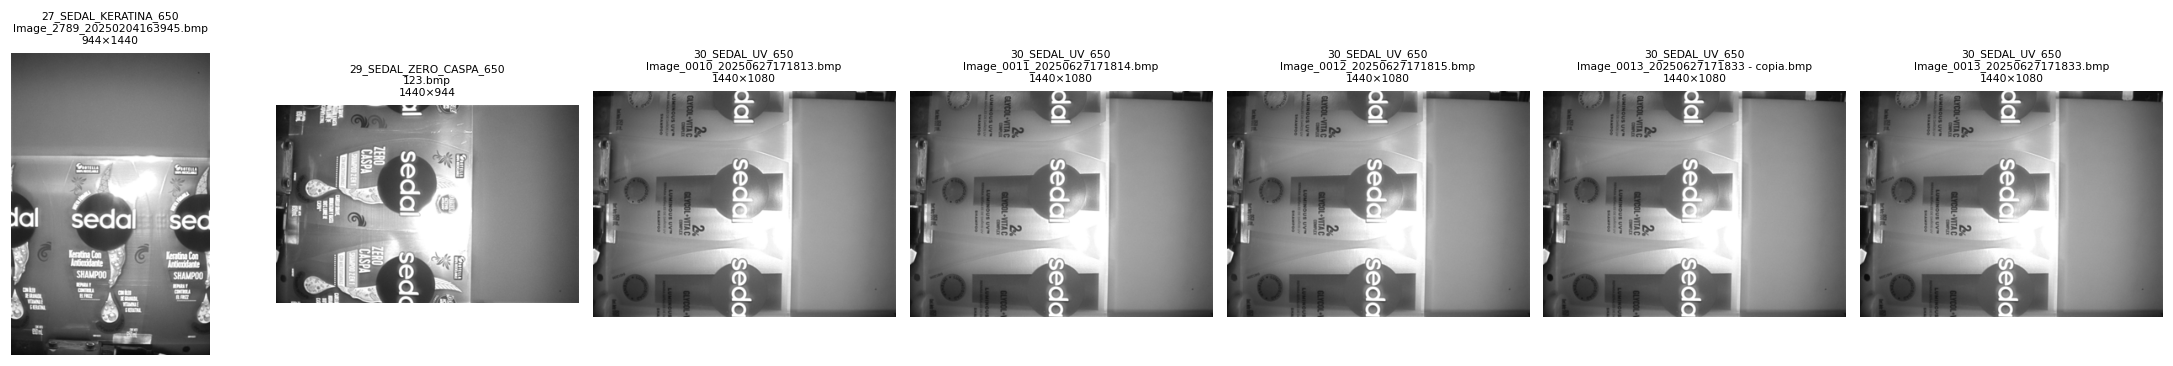

In [9]:
# ── 1.2b Las excepciones de geometría y de nombre ──
raras = inv[(inv.ancho != ANCHO_NATIVO) | (inv.alto != ALTO_NATIVO) | (inv.indice < 0)]
print(f'{len(raras)} archivos fuera de la norma 1440×944 o sin marca de tiempo:')
display(raras[['carpeta','archivo','ancho','alto','bytes','indice','marca_tiempo','media','desv']])

print('\nCarpetas afectadas:', sorted(raras.carpeta.unique()))

fig, ejes = plt.subplots(1, len(raras), figsize=(2.9 * len(raras), 3.4))
for eje, (_, r) in zip(np.atleast_1d(ejes), raras.iterrows()):
    im = Image.open(RAIZ / r.ruta).convert('L')
    eje.imshow(np.asarray(im.resize((im.width // 4, im.height // 4))),
               cmap='gray', vmin=0, vmax=255)
    eje.set_title(f'{r.carpeta}\n{r.archivo}\n{r.ancho}×{r.alto}', fontsize=7)
    eje.axis('off')
plt.tight_layout(); plt.show()


#### Lectura de resultados: las excepciones

El código lista los archivos que no miden 1440×944 o que no tienen marca de tiempo, y
muestra cada uno.

Son siete, en tres carpetas, y responden a causas distintas. Las cinco imágenes de
1440×1080 están en `30_SEDAL_UV_650`: cuatro capturas del 27 de junio de 2025 entre
las 17:18:13 y las 17:18:33 y una copia de una de ellas. 1080 es la altura completa
del sensor, así que se guardaron sin el recorte vertical habitual. La imagen de
944×1440, en `27_SEDAL_KERATINA_650`, pesa lo mismo que las demás y tiene el contenido
girado 90°: son los mismos píxeles rotados después de guardarla. `123.bmp`, en
`29_SEDAL_ZERO_CASPA_650`, tiene geometría normal pero perdió el nombre de la cámara,
y con él su índice y su hora. Sin hora no se le puede asignar jornada ni sesión.

In [10]:
# ── 1.2c Rastros de manipulación manual en todo el conjunto ──
foco = ['27_SEDAL_KERATINA_650', '29_SEDAL_ZERO_CASPA_650', '30_SEDAL_UV_650']
sub = inv[inv.carpeta.isin(foco)].copy()
sub['geometria'] = sub.ancho.astype(str) + '×' + sub.alto.astype(str)
print('Composición de las tres carpetas afectadas:')
display(sub.groupby(['carpeta', 'geometria']).agg(
    imagenes=('archivo', 'size'),
    indice_min=('indice', 'min'), indice_max=('indice', 'max'),
    desde=('marca_tiempo', 'min'), hasta=('marca_tiempo', 'max')).reset_index())

patron_raro = r'copia|copy|\(\d+\)|\s-\s'
alterados = inv[inv.archivo.str.contains(patron_raro, case=False, regex=True)]
print(f'\nNombres con marca de duplicación manual en todo el conjunto: {len(alterados)}')
if len(alterados):
    display(alterados[['carpeta', 'archivo', 'ancho', 'alto', 'bytes']])

rep_idx = (inv[inv.indice >= 0].groupby(['carpeta', 'indice']).size()
             .rename('veces').reset_index().query('veces > 1'))
print(f'\nÍndices de captura repetidos dentro de una misma carpeta: {len(rep_idx)}')
if len(rep_idx):
    display(rep_idx.merge(inv[['carpeta','indice','archivo','marca_tiempo']],
                          on=['carpeta','indice']).sort_values(['carpeta','indice']))

Composición de las tres carpetas afectadas:


,carpeta,geometria,imagenes,indice_min,indice_max,desde,hasta
0,27_SEDAL_KERATINA_650,1440×944,201,0,2874,2024-12-28 18:50:16,2025-07-11 20:40:09
1,27_SEDAL_KERATINA_650,944×1440,1,2789,2789,2025-02-04 16:39:45,2025-02-04 16:39:45
2,29_SEDAL_ZERO_CASPA_650,1440×944,39,-1,111,2025-02-04 20:40:01,2025-07-11 21:07:12
3,30_SEDAL_UV_650,1440×1080,5,10,13,2025-06-27 17:18:13,2025-06-27 17:18:33
4,30_SEDAL_UV_650,1440×944,35,0,23,2025-06-13 17:21:16,2025-06-27 17:31:34



Nombres con marca de duplicación manual en todo el conjunto: 9


,carpeta,archivo,ancho,alto,bytes
754,1_ANTICASPA_SAVITAL_510,Image_1318_20250115142455 - copia.bmp,1440,944,4078134
756,1_ANTICASPA_SAVITAL_510,Image_1319_20250115142456 - copia.bmp,1440,944,4078134
758,1_ANTICASPA_SAVITAL_510,Image_1320_20250115142457 - copia.bmp,1440,944,4078134
1491,30_SEDAL_UV_650,Image_0000_20250627173124 - copia.bmp,1440,944,4078134
1494,30_SEDAL_UV_650,Image_0001_20250627173127 - copia.bmp,1440,944,4078134
1497,30_SEDAL_UV_650,Image_0002_20250627173131 - copia.bmp,1440,944,4078134
1500,30_SEDAL_UV_650,Image_0003_20250627173132 - copia.bmp,1440,944,4078134
1503,30_SEDAL_UV_650,Image_0004_20250627173134 - copia.bmp,1440,944,4078134
1517,30_SEDAL_UV_650,Image_0013_20250627171833 - copia.bmp,1440,1080,4665654



Índices de captura repetidos dentro de una misma carpeta: 189


,carpeta,indice,veces,archivo,marca_tiempo
0,0_MULTIVIAMINAS_SAVITAL_510,0,2,Image_0000_20241228162832.bmp,2024-12-28 16:28:32
1,0_MULTIVIAMINAS_SAVITAL_510,0,2,Image_0000_20241228180204.bmp,2024-12-28 18:02:04
2,0_MULTIVIAMINAS_SAVITAL_510,1,2,Image_0001_20241228162833.bmp,2024-12-28 16:28:33
3,0_MULTIVIAMINAS_SAVITAL_510,1,2,Image_0001_20241228180205.bmp,2024-12-28 18:02:05
4,13_DOVE_NUTRICION_370,74,2,Image_0074_20250711222949.bmp,2025-07-11 22:29:49
...,...,...,...,...,...
416,9_ANTICASPA_LIMPIEZA_SAVITAL_510,22,2,Imagen_0022_20250325215806.bmp,2025-03-25 21:58:06
417,9_ANTICASPA_LIMPIEZA_SAVITAL_510,23,2,Image_0023_20250325201922.bmp,2025-03-25 20:19:22
418,9_ANTICASPA_LIMPIEZA_SAVITAL_510,23,2,Imagen_0023_20250325215806.bmp,2025-03-25 21:58:06
419,9_ANTICASPA_LIMPIEZA_SAVITAL_510,24,2,Image_0024_20250325201924.bmp,2025-03-25 20:19:24


#### Lectura de resultados: rastros de manipulación

El código describe las tres carpetas con excepciones, busca en todo el conjunto
nombres con marcas de duplicación manual ("copia", "copy", "(1)") y cuenta los
índices de captura que se repiten dentro de una misma carpeta.

Hay nueve archivos con el sufijo " - copia", que es el que agrega el Explorador de
Windows en español al duplicar un archivo: tres en `1_ANTICASPA_SAVITAL_510` y seis en
`30_SEDAL_UV_650`. Los índices repetidos son muchos más, 189, pero ese conteo no
significa duplicación: la celda siguiente muestra que casi todos corresponden a
sesiones distintas.

In [11]:
# ── 1.2d Qué significan los índices repetidos ──
inv['prefijo'] = inv.archivo.str.extract(r'^(Imagen|Image)_', expand=False).fillna('sin patrón')
print('Prefijo escrito por la cámara:')
print(inv.prefijo.value_counts().to_string(), '\n')

reales = (inv[inv.indice >= 0]
          .groupby(['carpeta', 'indice', 'marca_tiempo']).size()
          .rename('veces').reset_index().query('veces > 1'))
print(f'Mismo índice Y misma marca de tiempo (duplicación real): {len(reales)}')
display(reales)

orden = inv[inv.indice >= 0].sort_values(['carpeta', 'marca_tiempo']).copy()
orden['reinicio'] = (orden.groupby('carpeta').indice.diff().lt(0)
                     | orden.groupby('carpeta').cumcount().eq(0))
print('\nReinicios del contador por carpeta (cada uno abre una sesión de captura):')
display(orden.groupby('carpeta').reinicio.sum().rename('sesiones').reset_index())

Prefijo escrito por la cámara:
prefijo
Image         2413
Imagen         191
sin patrón       1 

Mismo índice Y misma marca de tiempo (duplicación real): 9


,carpeta,indice,marca_tiempo,veces
754,1_ANTICASPA_SAVITAL_510,1318,2025-01-15 14:24:55,2
755,1_ANTICASPA_SAVITAL_510,1319,2025-01-15 14:24:56,2
756,1_ANTICASPA_SAVITAL_510,1320,2025-01-15 14:24:57,2
1487,30_SEDAL_UV_650,0,2025-06-27 17:31:24,2
1489,30_SEDAL_UV_650,1,2025-06-27 17:31:27,2
1491,30_SEDAL_UV_650,2,2025-06-27 17:31:31,2
1493,30_SEDAL_UV_650,3,2025-06-27 17:31:32,2
1495,30_SEDAL_UV_650,4,2025-06-27 17:31:34,2
1508,30_SEDAL_UV_650,13,2025-06-27 17:18:33,2



Reinicios del contador por carpeta (cada uno abre una sesión de captura):


,carpeta,sesiones
0,0_MULTIVIAMINAS_SAVITAL_510,2
1,10_COLAGENO_SAVITAL_510,1
2,11_SERUM_SAVITAL_490,1
3,12_ELIXIR_SAVITAL_510,1
4,13_DOVE_NUTRICION_370,3
5,14_DOVE_RECONSTRUCCION_370,2
6,15_DOVE_REGENERACION_370,2
7,16_DOVE_REPAIR_350,1
8,17_DOVE_HIDRA_SUAVE_370,2
9,18_DOVE_HIDRA_370,1


#### Lectura de resultados: índices repetidos y prefijos

El código separa dos situaciones que la celda anterior mezclaba. Un mismo índice con
horas distintas indica que el contador de la cámara se reinició al empezar otra
sesión. Un mismo índice con la misma hora solo puede ser una copia del archivo.

Con ese criterio quedan nueve duplicaciones reales, que son exactamente los nueve
archivos " - copia". Los reinicios del contador suman 74 en todo el conjunto, y son un
mínimo del número de sesiones: una sesión nueva no siempre reinicia el contador. La
sección 1.5, que separa sesiones por huecos de tiempo, encuentra 95.

La cámara escribió dos prefijos distintos: `Image_` en 2.413 archivos e `Imagen_` en
191.

### 1.3 Duplicados exactos

Dos archivos con la misma huella MD5 tienen los mismos bytes, sin excepción.
No es un parecido visual: es el mismo archivo guardado dos veces. Importa por
dos razones. Dentro de una carpeta, una copia infla el conteo de una clase y,
si cae en particiones distintas, el modelo evalúa sobre una imagen que ya vio.
Entre carpetas distintas, significa que la misma imagen está etiquetada con
dos clases, y eso ya no es redundancia sino una contradicción en las etiquetas.

In [12]:
# ── 1.3 Duplicados exactos (huella MD5) ──
grupos = (inv.groupby('md5').size().rename('copias')
            .reset_index().query('copias > 1'))
dup = inv[inv.md5.isin(grupos.md5)].sort_values(['md5', 'carpeta', 'archivo'])
print(f'Huellas repetidas: {len(grupos)} · archivos involucrados: {len(dup)} · '
      f'sobrantes: {len(dup) - len(grupos)}')

carpetas_por_huella = dup.groupby('md5').carpeta.nunique()
print(f'\nGrupos dentro de una misma carpeta (redundancia): '
      f'{int((carpetas_por_huella == 1).sum())}')
print(f'Grupos que cruzan carpetas distintas (etiquetas en conflicto): '
      f'{int((carpetas_por_huella > 1).sum())}')

cruzados = dup[dup.md5.isin(carpetas_por_huella[carpetas_por_huella > 1].index)]
if len(cruzados):
    print('\nCarpetas implicadas en el conflicto:',
          sorted(cruzados.carpeta.unique()))
display(dup[['md5', 'carpeta', 'archivo', 'marca_tiempo', 'ancho', 'alto']].head(40))

Huellas repetidas: 140 · archivos involucrados: 303 · sobrantes: 163

Grupos dentro de una misma carpeta (redundancia): 113
Grupos que cruzan carpetas distintas (etiquetas en conflicto): 27

Carpetas implicadas en el conflicto: ['22_SEDAL_PREBIOTICOS_340', '28_SEDAL_PROBIOTICOS_650']


,md5,carpeta,archivo,marca_tiempo,ancho,alto
869,025aa70c12a41ca8d6dff865750277d8,21_SEDAL_RIZOS_DEFINIDOS_340,Image_0066_20250717160818.bmp,2025-07-17 16:08:18,1440,944
873,025aa70c12a41ca8d6dff865750277d8,21_SEDAL_RIZOS_DEFINIDOS_340,Image_0070_20250717160825.bmp,2025-07-17 16:08:25,1440,944
887,025aa70c12a41ca8d6dff865750277d8,21_SEDAL_RIZOS_DEFINIDOS_340,Image_0091_20250711212559.bmp,2025-07-11 21:25:59,1440,944
891,025aa70c12a41ca8d6dff865750277d8,21_SEDAL_RIZOS_DEFINIDOS_340,Image_0095_20250711212620.bmp,2025-07-11 21:26:20,1440,944
955,0472d737282ee0e9e2deeec73d72fcfd,22_SEDAL_PREBIOTICOS_340,Image_0840_20241228185618.bmp,2024-12-28 18:56:18,1440,944
1378,0472d737282ee0e9e2deeec73d72fcfd,28_SEDAL_PROBIOTICOS_650,Image_0840_20241228185618.bmp,2024-12-28 18:56:18,1440,944
947,07e008fc9b8d46210f1a3d54e43a53c9,22_SEDAL_PREBIOTICOS_340,Image_0832_20241228185610.bmp,2024-12-28 18:56:10,1440,944
1370,07e008fc9b8d46210f1a3d54e43a53c9,28_SEDAL_PROBIOTICOS_650,Image_0832_20241228185610.bmp,2024-12-28 18:56:10,1440,944
1088,0cb0f7f5edc1cb7cb39d296cab894d80,25_SEDAL_KERATINA_340,Image_0022_20250416142307.bmp,2025-04-16 14:23:07,1440,944
1092,0cb0f7f5edc1cb7cb39d296cab894d80,25_SEDAL_KERATINA_340,Image_0026_20250416142347.bmp,2025-04-16 14:23:47,1440,944


#### Lectura de resultados: duplicados exactos

El código agrupa los archivos por huella MD5. Dos archivos con la misma huella tienen
los mismos bytes: son el mismo archivo guardado dos veces, aunque tengan nombres,
carpetas y horas distintas.

Hay 140 huellas repetidas, que reúnen 303 archivos. Si se conserva uno por huella,
sobran 163 y quedan 2.442 imágenes con contenido distinto. 113 de los grupos están
dentro de una misma carpeta y son redundancia. Los otros 27 cruzan carpetas, todos
entre `22_SEDAL_PREBIOTICOS_340` y `28_SEDAL_PROBIOTICOS_650`: la misma imagen está
etiquetada con dos referencias. Como esas imágenes muestran 650 ml, se conservan en
la carpeta 28.

In [13]:
# ¿Cuándo escribió la cámara "Imagen_" en vez de "Image_"?
pre = (inv[inv.prefijo != 'sin patrón']
         .assign(dia=inv.marca_tiempo.dt.date)
         .groupby(['prefijo', 'dia']).size().rename('imagenes').reset_index())
display(pre.pivot(index='dia', columns='prefijo', values='imagenes').fillna(0).astype(int))
print('\nCarpetas con prefijo Imagen_:',
      sorted(inv.loc[inv.prefijo == 'Imagen', 'carpeta'].unique()))

prefijo,Image,Imagen
dia,,
2024-12-28,626,0
2024-12-30,209,0
2025-01-10,107,0
2025-01-15,33,0
2025-02-03,175,0
2025-02-04,100,13
2025-02-25,28,17
2025-02-26,185,14
2025-03-25,86,47



Carpetas con prefijo Imagen_: ['13_DOVE_NUTRICION_370', '14_DOVE_RECONSTRUCCION_370', '26_SEDAL_LISO_PERFECTO_340', '27_SEDAL_KERATINA_650', '29_SEDAL_ZERO_CASPA_650', '39_SAVILE_CONTROL_CASPA_510', '40_SAVILE_SABILA_510', '9_ANTICASPA_LIMPIEZA_SAVITAL_510']


#### Lectura de resultados: los dos prefijos

El código cuenta, por día, cuántos archivos llevan cada prefijo.

`Imagen_` aparece en 7 de las 18 jornadas, y en cinco de ellas convive con `Image_` el
mismo día. Solo el 14 y el 21 de julio de 2025 son únicamente `Imagen_`. El prefijo no
marca entonces un cambio en una fecha, sino dos configuraciones del trabajo de la
cámara usadas en paralelo. Sirve como marcador adicional de sesión.

In [14]:
# ── 1.3b Naturaleza de los duplicados dentro de una misma carpeta ──
internos = dup[dup.md5.isin(carpetas_por_huella[carpetas_por_huella == 1].index)]

res = (internos.groupby('md5')
         .agg(carpeta=('carpeta', 'first'), copias=('archivo', 'size'),
              desde=('marca_tiempo', 'min'), hasta=('marca_tiempo', 'max'),
              indices=('indice', lambda s: sorted(s.tolist()))))
res['segundos'] = (res.hasta - res.desde).dt.total_seconds()
res['dias_distintos'] = res.desde.dt.date != res.hasta.dt.date

print(f'Grupos internos: {len(res)} · en {internos.carpeta.nunique()} carpetas '
      f'de {inv.carpeta.nunique()}')
print(f'Grupos cuyas copias caen en días distintos: {int(res.dias_distintos.sum())}')
print('\nSeparación temporal dentro de cada grupo (segundos):')
print(res.segundos.describe().to_string())

print('\nLos de mayor separación:')
display(res.sort_values('segundos', ascending=False).head(15))

print('\nArchivos duplicados por carpeta:')
display(internos.groupby('carpeta').size().rename('archivos')
                .sort_values(ascending=False).to_frame())

Grupos internos: 113 · en 19 carpetas de 43
Grupos cuyas copias caen en días distintos: 14

Separación temporal dentro de cada grupo (segundos):
count       113.000000
mean      62144.486726
std      165148.262586
min           0.000000
25%          32.000000
50%          53.000000
75%         214.000000
max      499374.000000

Los de mayor separación:


,carpeta,copias,desde,hasta,indices,segundos,dias_distintos
md5,,,,,,,
c85bc36a6d0a2f5367c5918ecc02f992,21_SEDAL_RIZOS_DEFINIDOS_340,2,2025-07-11 21:25:05,2025-07-17 16:07:59,"[54, 79]",499374.0,True
76cb7b5fd0d663ee0646eb3fdccf6995,21_SEDAL_RIZOS_DEFINIDOS_340,4,2025-07-11 21:25:31,2025-07-17 16:08:23,"[59, 69, 84, 94]",499372.0,True
3eddf2f4899d93ecafb519d29794bab0,21_SEDAL_RIZOS_DEFINIDOS_340,4,2025-07-11 21:25:30,2025-07-17 16:08:21,"[58, 68, 83, 93]",499371.0,True
5edeb910ee217af3f77b9650db0a336e,21_SEDAL_RIZOS_DEFINIDOS_340,2,2025-07-11 21:25:34,2025-07-17 16:08:12,"[62, 87]",499358.0,True
1891d415d42f7b6541f2b969c0643906,21_SEDAL_RIZOS_DEFINIDOS_340,2,2025-07-11 21:25:32,2025-07-17 16:08:09,"[60, 85]",499357.0,True
98e2a2e2fd98488f78865bc2b64b2481,21_SEDAL_RIZOS_DEFINIDOS_340,2,2025-07-11 21:25:33,2025-07-17 16:08:10,"[61, 86]",499357.0,True
d8bef7380c436faf360eef559987922c,21_SEDAL_RIZOS_DEFINIDOS_340,2,2025-07-11 21:25:29,2025-07-17 16:08:04,"[57, 82]",499355.0,True
3595c6b5099b9cc4925d6755aaa4db14,21_SEDAL_RIZOS_DEFINIDOS_340,2,2025-07-11 21:25:27,2025-07-17 16:08:01,"[55, 80]",499354.0,True
76a626a14481011dad5a87c4ef627180,21_SEDAL_RIZOS_DEFINIDOS_340,2,2025-07-11 21:25:28,2025-07-17 16:08:02,"[56, 81]",499354.0,True



Archivos duplicados por carpeta:


,archivos
carpeta,
21_SEDAL_RIZOS_DEFINIDOS_340,36
27_SEDAL_KERATINA_650,25
17_DOVE_HIDRA_SUAVE_370,20
20_SEDAL_ZERO_CASPA_340,18
29_SEDAL_ZERO_CASPA_650,18
23_SEDAL_MADRE_340,16
30_SEDAL_UV_650,12
32_SEDAL_MADRES_650,12
15_DOVE_REGENERACION_370,10


#### Lectura de resultados: cómo son los duplicados internos

El código mide, para cada grupo de archivos idénticos de una carpeta, cuánto tiempo
separa al primero del último, y cuenta en qué carpetas aparecen.

Los 113 grupos están en 19 de las 43 carpetas. La mitad tiene sus copias a menos de
53 segundos entre sí, y tres cuartas partes a menos de 214 segundos. Catorce grupos
cruzan días distintos, con una separación máxima de 5,8 días, y casi todos están en
`21_SEDAL_RIZOS_DEFINIDOS_340`. Esa carpeta es la de más archivos implicados, 36,
seguida por la 27 con 25 y la 17 con 20.


MISMA HUELLA MD5
  Image_0008_20250613200649.bmp  vs  Image_0016_20250613200725.bmp   (36 s de diferencia)
  bytes idénticos ........ True
  píxeles distintos ...... 0 (0.00 % de la imagen)
  diferencia máxima ...... 0 niveles de gris
  RMSE ................... 0.0000

CAPTURAS CONSECUTIVAS, HUELLAS DISTINTAS
  Image_0010_20250613200653.bmp  vs  Image_0011_20250613200654.bmp   (1 s de diferencia)
  bytes idénticos ........ False
  píxeles distintos ...... 1,299,457 (95.59 % de la imagen)
  diferencia máxima ...... 154 niveles de gris
  RMSE ................... 30.7094


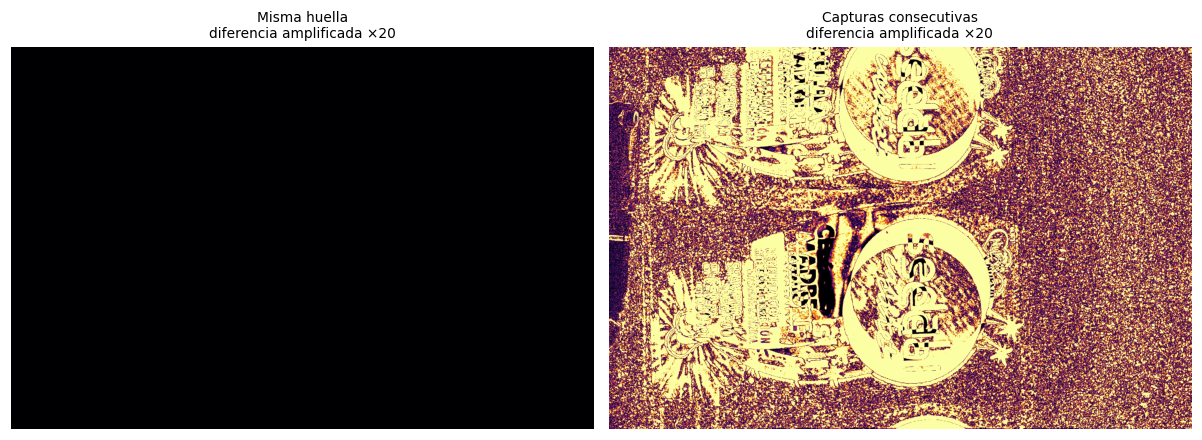

In [15]:
# ── 1.3c ¿Duplicado exacto o captura consecutiva? ──
# Compara una pareja con la misma huella contra una pareja de capturas
# consecutivas de la misma carpeta que sí tienen huellas distintas.

grupo  = res.sort_values('copias', ascending=False).index[0]
pareja = internos[internos.md5 == grupo].sort_values('marca_tiempo')
carp   = pareja.carpeta.iloc[0]
an, al = int(pareja.ancho.iloc[0]), int(pareja.alto.iloc[0])

v = (inv[(inv.carpeta == carp) & (inv.ancho == an) & (inv.alto == al)
         & (~inv.md5.isin(res.index))].sort_values('marca_tiempo').copy())
v['hueco'] = v.marca_tiempo.diff().dt.total_seconds()
pos    = v.index.get_loc(v.hueco.idxmin())
consec = v.iloc[[pos - 1, pos]]

cargar = lambda r: np.asarray(Image.open(RAIZ / r.ruta).convert('L'), dtype=np.int16)

def comparar(r1, r2, etiqueta):
    x, y = cargar(r1), cargar(r2)
    dif = np.abs(x - y)
    iguales = (RAIZ / r1.ruta).read_bytes() == (RAIZ / r2.ruta).read_bytes()
    seg = abs((r2.marca_tiempo - r1.marca_tiempo).total_seconds())
    print(f'\n{etiqueta}')
    print(f'  {r1.archivo}  vs  {r2.archivo}   ({seg:.0f} s de diferencia)')
    print(f'  bytes idénticos ........ {iguales}')
    print(f'  píxeles distintos ...... {int((dif > 0).sum()):,} '
          f'({(dif > 0).mean()*100:.2f} % de la imagen)')
    print(f'  diferencia máxima ...... {int(dif.max())} niveles de gris')
    print(f'  RMSE ................... {np.sqrt((dif.astype(float)**2).mean()):.4f}')
    return dif

d1 = comparar(pareja.iloc[0], pareja.iloc[1], 'MISMA HUELLA MD5')
d2 = comparar(consec.iloc[0], consec.iloc[1], 'CAPTURAS CONSECUTIVAS, HUELLAS DISTINTAS')

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, d, t in zip(ejes, [d1, d2], ['Misma huella', 'Capturas consecutivas']):
    eje.imshow(np.clip(d * 20, 0, 255), cmap='inferno', vmin=0, vmax=255)
    eje.set_title(f'{t}\ndiferencia amplificada ×20', fontsize=9)
    eje.axis('off')
plt.tight_layout(); plt.show()

#### Lectura de resultados: duplicado frente a captura consecutiva

El código compara píxel a píxel dos parejas de la misma carpeta: una con la misma
huella y otra de dos capturas consecutivas con huellas distintas. Las imágenes de la
figura muestran la diferencia absoluta multiplicada por 20 para hacerla visible.

La pareja con la misma huella, separada por 36 segundos, no difiere en ningún píxel:
RMSE de 0 y un rectángulo negro en la figura. La pareja consecutiva, separada por un
segundo, difiere en el 95,6 % de los píxeles, con una diferencia máxima de 154 niveles
de gris y un RMSE de 30,7. En la figura se ve el contorno completo de la etiqueta,
porque el producto cambió de posición entre una captura y la otra. Las capturas
consecutivas no son copias. Este resultado proviene de una sola pareja de cada tipo;
la sección 1.4 mide la diferencia en todas las parejas vecinas.

In [16]:
# ── 1.3d ¿De qué depende la duplicación? ──
res['dia'] = res.desde.dt.date
print('Grupos duplicados por jornada:')
display(res.groupby('dia').size().rename('grupos').to_frame())

print('Proporción de archivos duplicados según la configuración de la cámara:')
for p in ['Image', 'Imagen']:
    tot = int((inv.prefijo == p).sum())
    d   = int((internos.prefijo == p).sum())
    print(f'  {p:7s} {d:4d} de {tot:5d} = {100*d/tot:5.1f} %')

c21 = inv[inv.carpeta == '21_SEDAL_RIZOS_DEFINIDOS_340']
print(f'\n21_SEDAL_RIZOS_DEFINIDOS_340: {len(c21)} imágenes, '
      f'{c21.md5.nunique()} huellas distintas')
display(c21.groupby(c21.marca_tiempo.dt.date).agg(
    imagenes=('archivo', 'size'), huellas=('md5', 'nunique'),
    indice_min=('indice', 'min'), indice_max=('indice', 'max'),
    desde=('marca_tiempo', 'min'), hasta=('marca_tiempo', 'max')))

Grupos duplicados por jornada:


,grupos
dia,
2025-01-15,3
2025-02-03,15
2025-02-04,8
2025-02-25,5
2025-02-26,5
2025-03-25,4
2025-04-16,4
2025-06-13,12
2025-06-27,11


Proporción de archivos duplicados según la configuración de la cámara:
  Image    228 de  2413 =   9.4 %
  Imagen    20 de   191 =  10.5 %

21_SEDAL_RIZOS_DEFINIDOS_340: 66 imágenes, 44 huellas distintas


,imagenes,huellas,indice_min,indice_max,desde,hasta
marca_tiempo,,,,,,
2024-12-28,30,30,761,790,2024-12-28 18:52:00,2024-12-28 18:52:29
2025-07-11,18,14,79,96,2025-07-11 21:25:05,2025-07-11 21:26:21
2025-07-17,18,14,54,71,2025-07-17 16:07:59,2025-07-17 16:08:26


#### Lectura de resultados: de qué depende la duplicación

El código cuenta los grupos duplicados por jornada, compara la proporción de
duplicados entre los dos prefijos y describe por día la carpeta 21.

Ninguna de las 835 imágenes de diciembre de 2024 está duplicada. Desde el 15 de enero
de 2025 aparecen grupos en todas las jornadas, con un máximo de 38 el 11 de julio. El
prefijo no explica el fenómeno: `Image_` duplica el 9,4 % de sus archivos e `Imagen_`
el 10,5 %.

La carpeta 21 tiene 66 archivos y 44 contenidos distintos. Las 30 imágenes del 28 de
diciembre son todas distintas, con índices consecutivos. Las sesiones del 11 y del
17 de julio tienen 18 archivos cada una, con 14 contenidos distintos, y son idénticas
entre sí. Entre una fecha y la otra el contador retrocede: el 11 de julio va de 79 a
96 y el 17 de julio, de 54 a 71. Para la partición, esas dos sesiones cuentan como una
sola.

In [17]:
# ── Comprobación: ¿el MD5 encuentra lo que el nombre ya delataba? ──
copias = inv[inv.archivo.str.contains('copia', case=False)]
en_grupo = copias.md5.isin(dup.md5)
print(f'Archivos " - copia": {len(copias)} · con huella repetida: {int(en_grupo.sum())}')
display(copias.loc[~en_grupo, ['carpeta', 'archivo']])

# ── Comprobación: ¿la imagen 944×1440 es una rotación de otra de su carpeta? ──
rara = inv[(inv.ancho == 944) & (inv.alto == 1440)].iloc[0]
px = np.asarray(Image.open(RAIZ / rara.ruta).convert('RGB'))
candidatas = inv[(inv.carpeta == rara.carpeta) & (inv.ancho == 1440) & (inv.alto == 944)]
hallada = None
for _, c in candidatas.iterrows():
    otra = np.asarray(Image.open(RAIZ / c.ruta).convert('RGB'))
    for k in (1, 3):
        if np.array_equal(np.rot90(px, k), otra):
            hallada = (c.archivo, 90 * k)
            break
    if hallada: break
print('\nRotación idéntica de otra imagen de la carpeta:',
      hallada if hallada else 'no se encontró ninguna (de las 201 comparadas)')

Archivos " - copia": 9 · con huella repetida: 9


,carpeta,archivo



Rotación idéntica de otra imagen de la carpeta: no se encontró ninguna (de las 201 comparadas)


#### Lectura de resultados: validación del criterio MD5

El código revisa si los archivos que ya sabíamos copiados por su nombre aparecen entre
los grupos de huella repetida, y si la imagen de 944×1440 es una rotación exacta de
otra de su carpeta.

Los nueve archivos " - copia" tienen huella repetida. El MD5 encontró, solo por
contenido, todas las copias que el nombre delataba, lo que respalda los 154 sobrantes
que encontró sin esa ayuda. La imagen girada no coincide con ninguna de las 201
imágenes de su carpeta rotadas 90° en ninguno de los dos sentidos: es una captura
propia que alguien giró, no la copia de otra.

### 1.3e Problemas de integridad observados por carpeta

Estado al 20 de octubre de 2026. La columna "archivos implicados" cuenta todos los
archivos que pertenecen a un grupo de huella MD5 repetida dentro de la carpeta,
originales incluidos; no es el número de sobrantes. Las 23 carpetas que no aparecen
no presentaron problemas en las pruebas de formato, nombre ni huella.

| Carpeta | Problemas observados | Archivos implicados |
|---|---|---|
| 1_ANTICASPA_SAVITAL_510 | 3 copias manuales con sufijo " - copia" (índices 1318 a 1320, 15 ene 2025) | 6 |
| 8_ARGAN_SAVITAL_510 | Archivos con contenido idéntico y nombres distintos | 8 |
| 9_ANTICASPA_LIMPIEZA_SAVITAL_510 | Archivos con contenido idéntico y nombres distintos | 8 |
| 13_DOVE_NUTRICION_370 | Archivos con contenido idéntico y nombres distintos | 8 |
| 15_DOVE_REGENERACION_370 | Archivos con contenido idéntico y nombres distintos | 10 |
| 17_DOVE_HIDRA_SUAVE_370 | Archivos con contenido idéntico y nombres distintos | 20 |
| 20_SEDAL_ZERO_CASPA_340 | Archivos con contenido idéntico y nombres distintos | 18 |
| 21_SEDAL_RIZOS_DEFINIDOS_340 | Las sesiones del 11 y del 17 de julio de 2025 son idénticas archivo por archivo (18 cada una), con el contador retrocediendo entre fechas. 66 archivos, 44 contenidos distintos | 36 |
| 22_SEDAL_PREBIOTICOS_340 | 27 imágenes idénticas a otras de la carpeta 28 (28 dic 2024, 18:56). Muestran 650 ml: se descartan de esta carpeta | — |
| 23_SEDAL_MADRE_340 | Archivos con contenido idéntico y nombres distintos | 16 |
| 24_SEDAL_DUO_340 | Archivos con contenido idéntico y nombres distintos | 8 |
| 25_SEDAL_KERATINA_340 | Archivos con contenido idéntico y nombres distintos | 8 |
| 27_SEDAL_KERATINA_650 | `Image_2789_20250204163945.bmp` girada 90° (944×1440); no es la rotación de ninguna otra imagen de la carpeta | 25 |
| 28_SEDAL_PROBIOTICOS_650 | Comparte 27 imágenes con la carpeta 22 (se conservan aquí). El nombre de la carpeta dice "Probióticos" y la etiqueta dice "Prebióticos + Biotina" | 8 |
| 29_SEDAL_ZERO_CASPA_650 | `123.bmp` sin índice ni hora de captura; renombrado, con fecha de modificación del 7 oct 2026 | 18 |
| 30_SEDAL_UV_650 | 6 copias manuales con sufijo " - copia". 4 capturas a 1440×1080 sin el recorte habitual (índices 0010 a 0013, 27 jun 2025, 17:18), más la copia de una de ellas | 12 |
| 32_SEDAL_MADRES_650 | Archivos con contenido idéntico y nombres distintos | 12 |
| 39_SAVILE_CONTROL_CASPA_510 | Archivos con contenido idéntico y nombres distintos | 10 |
| 40_SAVILE_SABILA_510 | Archivos con contenido idéntico y nombres distintos | 10 |
| 41_SAVILE_AGUACATE_510 | Archivos con contenido idéntico y nombres distintos | 8 |

### 1.5 Procedencia: jornadas, sesiones y ráfagas

El BMP no guarda metadatos, así que la única información temporal de cada imagen
es la fecha y hora escrita en su nombre. A partir de ella se reconstruyen tres
niveles de agrupación, cada uno contenido en el anterior:

| Nivel | Definición | Qué agrupa |
|---|---|---|
| Jornada | Día calendario de captura | Las condiciones de un día: montaje, iluminación, fondo |
| Sesión | Capturas de una misma carpeta separadas por menos de 10 minutos | Una corrida continua de una referencia |
| Ráfaga | Capturas separadas por menos de 3 segundos | Imágenes casi iguales, tomadas con la línea detenida o muy lenta |

Estos niveles importan para la partición: imágenes de una misma ráfaga o sesión
están correlacionadas, y si quedan repartidas entre entrenamiento y prueba el
modelo se evalúa sobre escenas que ya vio.

La reconstrucción supone que la hora del nombre corresponde al momento de la
captura. Eso está consultado con la empresa; mientras no haya respuesta, la
partición se hará por jornada completa, el nivel más conservador. `123.bmp` no
tiene hora y queda sin asignar.

In [13]:
# ── 1.5 Procedencia: jornada, sesión y ráfaga por imagen ──
inv = inv.sort_values(['carpeta', 'marca_tiempo']).reset_index(drop=True)
con_hora = inv.marca_tiempo.notna()

inv['hueco_s'] = inv.groupby('carpeta').marca_tiempo.diff().dt.total_seconds()
nueva_sesion = inv.hueco_s.isna() | (inv.hueco_s > CORTE_SESION)
nueva_rafaga = inv.hueco_s.isna() | (inv.hueco_s > CORTE_RAFAGA)

inv['sesion'] = nueva_sesion.groupby(inv.carpeta).cumsum()
inv['rafaga'] = nueva_rafaga.groupby([inv.carpeta, inv.sesion]).cumsum()

inv['id_jornada'] = inv.marca_tiempo.dt.strftime('%Y-%m-%d')
inv['id_sesion']  = inv.carpeta + '|S' + inv.sesion.astype(int).astype(str).str.zfill(2)
inv['id_rafaga']  = inv.id_sesion + '|R' + inv.rafaga.astype(int).astype(str).str.zfill(3)
inv.loc[~con_hora, ['id_jornada', 'id_sesion', 'id_rafaga']] = None

t = inv[con_hora]
print(f'Imágenes con hora: {len(t)} de {len(inv)}  ·  sin hora: {int((~con_hora).sum())}')
print(f'Jornadas: {t.id_jornada.nunique()}  ·  sesiones: {t.id_sesion.nunique()}  ·  '
      f'ráfagas: {t.id_rafaga.nunique()}')

huecos = t.hueco_s.dropna()
print(f'\nDisparos consecutivos a 1 s o menos: {(huecos <= 1).mean()*100:.1f} %')
largo = t.groupby('id_rafaga').size()
print(f'Ráfaga más larga: {largo.max()} imágenes  ({largo.idxmax()})')
print(f'Ráfagas de una sola imagen: {int((largo == 1).sum())}')

por_clase = (t.groupby('carpeta')
               .agg(imagenes=('archivo', 'size'), contenidos=('md5', 'nunique'),
                    jornadas=('id_jornada', 'nunique'), sesiones=('id_sesion', 'nunique'),
                    rafagas=('id_rafaga', 'nunique'),
                    primera=('marca_tiempo', 'min'), ultima=('marca_tiempo', 'max')))
print(f'\nClases con una sola jornada: {int((por_clase.jornadas == 1).sum())}  ·  '
      f'una sola sesión: {int((por_clase.sesiones == 1).sum())}  ·  '
      f'una sola ráfaga: {int((por_clase.rafagas == 1).sum())}')
display(por_clase.sort_values(['jornadas', 'sesiones', 'rafagas']))

Imágenes con hora: 2604 de 2605  ·  sin hora: 1
Jornadas: 18  ·  sesiones: 95  ·  ráfagas: 336

Disparos consecutivos a 1 s o menos: 69.9 %
Ráfaga más larga: 78 imágenes  (40_SAVILE_SABILA_510|S02|R009)
Ráfagas de una sola imagen: 118

Clases con una sola jornada: 19  ·  una sola sesión: 12  ·  una sola ráfaga: 8


,imagenes,contenidos,jornadas,sesiones,rafagas,primera,ultima
carpeta,,,,,,,
35_SAVILE_HIALURONICO_490,27,27,1,1,1,2024-12-28 18:24:44,2024-12-28 18:25:10
36_SAVILE_HIALURONICO_510,29,29,1,1,1,2024-12-28 18:28:19,2024-12-28 18:28:47
37_SAVILE_MULTI_510,46,46,1,1,1,2024-12-28 18:26:21,2024-12-28 18:27:06
38_SAVILE_ARGAN_490,24,24,1,1,1,2024-12-28 18:21:24,2024-12-28 18:21:47
3_FUSION_SAVITAL_490,41,41,1,1,1,2024-12-28 18:14:42,2024-12-28 18:15:24
5_HIALURONICO_SAVITAL_510,31,31,1,1,1,2024-12-28 18:08:49,2024-12-28 18:09:19
6_MULTIOLEOS_SAVITAL_510,24,24,1,1,1,2024-12-28 18:10:27,2024-12-28 18:10:50
7_SERUM_SAVITAL_490,51,51,1,1,1,2024-12-28 18:18:28,2024-12-28 18:19:18
12_ELIXIR_SAVITAL_510,19,19,1,1,2,2025-07-11 20:00:19,2025-07-11 20:00:46


#### Lectura de resultados: los tres niveles de procedencia

**Qué hace el código.** Ordena las imágenes de cada carpeta por la hora de su nombre
y calcula cuánto tiempo pasó desde la imagen anterior de esa misma carpeta. Si el
hueco supera 10 minutos, empieza una sesión nueva; si supera 3 segundos, empieza una
ráfaga nueva dentro de la sesión. La jornada es el día. Cada imagen queda con tres
identificadores, que la sección 2 usa para particionar.

**Qué muestra.** 2.604 de las 2.605 imágenes tienen hora; la que falta es `123.bmp`.
El conjunto se reparte en 18 jornadas, 95 sesiones y 336 ráfagas, las mismas cifras
del análisis exploratorio inicial, obtenidas aquí con un código distinto.

El 69,9 % de las capturas ocurre a un segundo o menos de la anterior, y la ráfaga más
larga encadena 78 imágenes (`40_SAVILE_SABILA_510`, sesión 2). Las imágenes de una
ráfaga muestran los mismos envases, con la misma luz, en posiciones algo desplazadas.
Por eso el número de imágenes exagera la información disponible:
`38_SAVILE_ARGAN_490` tiene 24 imágenes, todas tomadas en 23 segundos dentro de una
sola ráfaga. Se parece más a una escena vista 24 veces que a 24 ejemplos
independientes.

Las clases más pobres en procedencia son 19 con una sola jornada, 12 con una sola
sesión y 8 con una sola ráfaga. Esas ocho (3, 5, 6, 7, 35, 36, 37 y 38) son todas del
28 de diciembre de 2024 y cada una se capturó en menos de un minuto. La consecuencia
para la partición por jornada es directa: las 19 clases de una sola jornada quedan
completas en entrenamiento o completas en prueba. No hay forma de medir con ellas cómo
se comporta el modelo en un día que no vio, así que esa evaluación solo es posible
para 24 de las 43 clases.

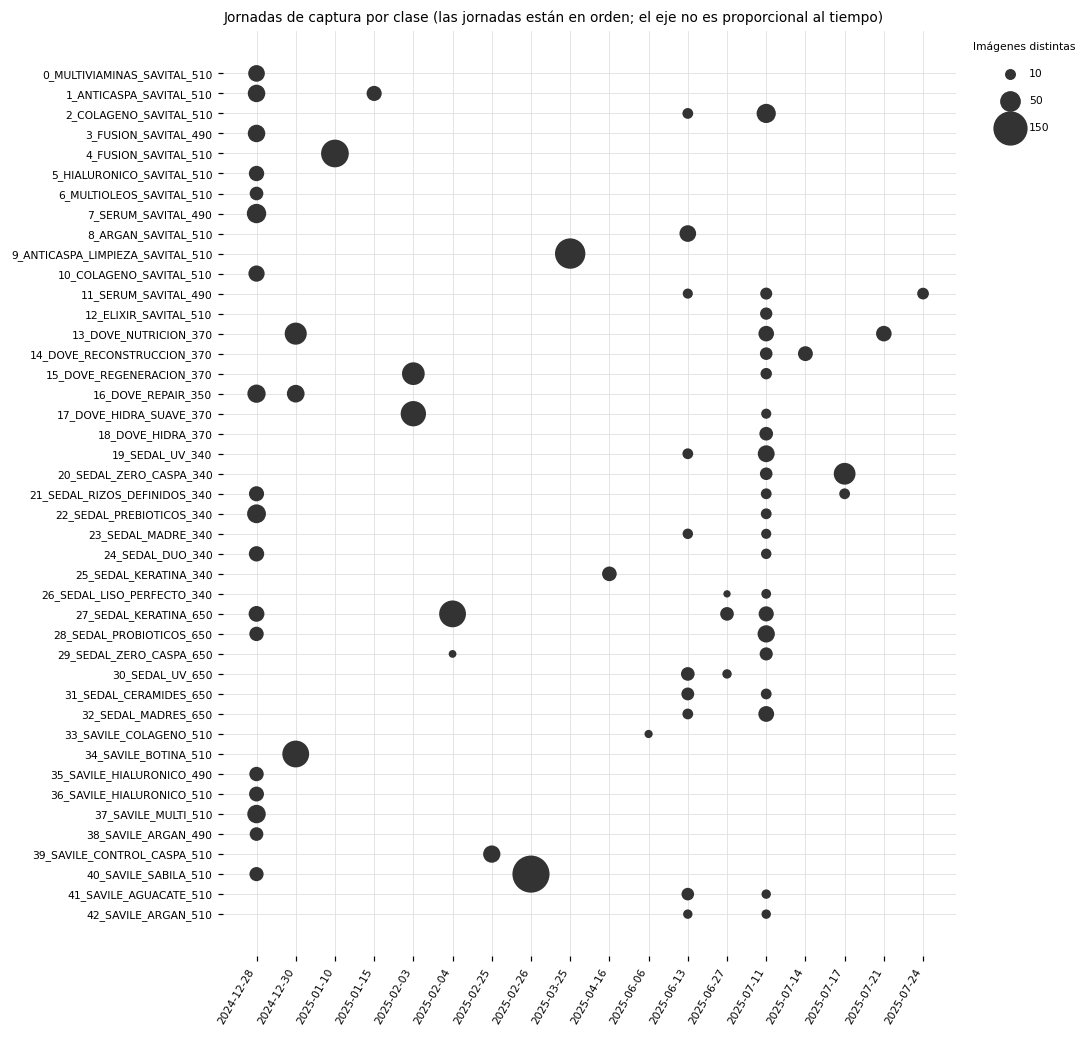

In [14]:
# ── Figura: en qué jornadas se capturó cada clase ──
cal = t.groupby(['carpeta', 'id_jornada']).md5.nunique().rename('n').reset_index()
clases = sorted(cal.carpeta.unique(), key=lambda c: int(c.split('_')[0]))
dias   = sorted(cal.id_jornada.unique())
pos_y  = {c: i for i, c in enumerate(clases)}
pos_x  = {d: i for i, d in enumerate(dias)}
tam    = lambda n: n * 3 + 8

fig, ax = plt.subplots(figsize=(10, 9.5))
ax.scatter(cal.id_jornada.map(pos_x), cal.carpeta.map(pos_y),
           s=tam(cal.n), color='#333333', linewidths=0)
ax.set_xticks(range(len(dias)))
ax.set_xticklabels(dias, rotation=60, ha='right', fontsize=7)
ax.set_yticks(range(len(clases)))
ax.set_yticklabels(clases, fontsize=7)
ax.invert_yaxis()
ax.grid(color='#dddddd', linewidth=0.5); ax.set_axisbelow(True)
for borde in ax.spines.values():
    borde.set_visible(False)
for n in (10, 50, 150):
    ax.scatter([], [], s=tam(n), color='#333333', label=f'{n}')
ax.legend(title='Imágenes distintas', loc='upper left', bbox_to_anchor=(1.01, 1),
          frameon=False, fontsize=7, title_fontsize=7, labelspacing=1.6)
ax.set_title('Jornadas de captura por clase (las jornadas están en orden; '
             'el eje no es proporcional al tiempo)', fontsize=9, loc='left')
plt.tight_layout()
plt.savefig(SALIDA / 'fig_calendario_capturas.png', dpi=200, bbox_inches='tight')
plt.show()

#### Lectura de resultados: calendario de capturas

**Qué hace el código.** Cuenta las imágenes distintas (por huella MD5) de cada clase
en cada jornada y dibuja un punto por combinación, con área proporcional al conteo.
Las jornadas están en orden pero equiespaciadas: la distancia horizontal entre
columnas no representa tiempo transcurrido.

**Qué muestra.** Dos jornadas concentran la mayor parte de las clases: la primera
columna, 28 de diciembre de 2024, y la del 11 de julio de 2025. Las demás reúnen
pocas clases cada una, y varias clases aparecen en una sola columna con un punto
grande, como 4, 9, 34 y 40.

Lo más importante está en los dos pares que solo se distinguen por el contenido neto.
Savital Fusión 490 (carpeta 3) se capturó únicamente el 28 de diciembre y su versión
de 510 (carpeta 4), únicamente el 10 de enero. Savital Sérum 490 (carpeta 7) también
es solo del 28 de diciembre, mientras que la carpeta 11, cuyos envases dicen 510 ml,
aparece el 13 de junio, el 11 de julio y el 24 de julio. En ninguno de los dos pares
las referencias comparten jornada. La referencia queda entonces confundida con el
día: cualquier diferencia entre esos días, de fondo, iluminación o montaje, separa
las clases igual de bien que la cifra impresa. Un modelo puede acertar el 100 % en
esos pares sin leer la etiqueta. Ya pasó en el análisis exploratorio inicial: un
vecino más cercano sobre píxeles separó el par Fusión con exactitud perfecta, y lo
que separaba era la fecha.

El par Hialurónico (35 y 36) sí comparte jornada, con cuatro minutos de diferencia,
pero esas dos carpetas son acondicionador y shampoo, con artes distintos. No ponen a
prueba el grano fino.

De aquí sale el pedido a la empresa de capturar en una misma sesión las dos
referencias de cada par fino. Sin esa captura, el conjunto no permite comprobar que
el modelo distingue 490 de 510 por el contenido neto.

### 1.6 Distribución de clases

Cuántas imágenes tiene cada clase depende de qué se cuente. Las 2.605 imágenes
incluyen 163 copias exactas, y una clase con muchas copias aparenta más ejemplos de
los que tiene. Aquí se cuentan imágenes distintas: se conserva una por huella MD5
dentro de cada carpeta, prefiriendo el archivo original sobre el que lleva " - copia"
y el de hora más temprana, y las 27 imágenes compartidas entre las carpetas 22 y 28
quedan solo en la 28.

Los casos consultados con la empresa (las cuatro capturas de 1440×1080 y `123.bmp`)
se marcan como pendientes y todavía se cuentan. La imagen girada se conserva, porque
se endereza en la preparación.

Junto al conteo se mide lo que más condiciona la evaluación: cuántas jornadas tiene
cada clase. Solo una clase con dos o más jornadas puede evaluarse en un día que el
modelo no vio durante el entrenamiento.

In [15]:
# ── 1.6 Distribución de clases ──

# 1) Nombres de clase corregidos (las carpetas originales no se modifican).
#    Cada corrección está respaldada por el texto impreso en la etiqueta del envase.
CORRECCIONES = {
    # Los envases dicen "cont. neto 510 mL" en sus tres jornadas (13 jun, 11 jul, 24 jul 2025)
    '11_SERUM_SAVITAL_490':     '11_SERUM_SAVITAL_510',
    # La etiqueta dice "Prebióticos + Biotina", no "Probióticos"; mismo producto que la 22, en 650 ml
    '28_SEDAL_PROBIOTICOS_650': '28_SEDAL_PREBIOTICOS_650',
}
inv['clase'] = inv.carpeta.replace(CORRECCIONES)
print('Clases renombradas:')
for antes, despues in CORRECCIONES.items():
    print(f'  {antes}  →  {despues}')

# 2) Descartes decididos: conflicto 22/28 y duplicados exactos.
#    Se conserva el original antes que la " - copia", y la imagen de hora más temprana.
inv['es_copia'] = inv.archivo.str.contains('copia', case=False)
inv['descarte'] = ''

md5_28 = set(inv.loc[inv.carpeta == '28_SEDAL_PROBIOTICOS_650', 'md5'])
conflicto = (inv.carpeta == '22_SEDAL_PREBIOTICOS_340') & inv.md5.isin(md5_28)
inv.loc[conflicto, 'descarte'] = 'conflicto 22/28'

orden = inv[~conflicto].sort_values(['carpeta', 'es_copia', 'marca_tiempo', 'archivo'])
repetido = orden.duplicated(['carpeta', 'md5'])
inv.loc[repetido[repetido].index, 'descarte'] = 'duplicado exacto'

print('\nDescartes:')
print(inv.descarte.replace('', 'se conserva').value_counts().to_string())
assert (inv.descarte != '').sum() == 163, 'El total de descartes no coincide con 1.3'

# 3) Pendientes: casos consultados con la empresa; se cuentan, pero quedan marcados.
inv['pendiente'] = ''
inv.loc[inv.alto == 1080, 'pendiente'] = 'resolución 1440×1080 (consultado)'
inv.loc[inv.marca_tiempo.isna(), 'pendiente'] = 'sin hora de captura (consultado)'
inv.loc[inv.ancho == 944, 'pendiente'] = 'girada 90° (se endereza)'

util = inv[inv.descarte == '']
print(f'\nImágenes distintas que quedan: {len(util)}')
print('Pendientes entre ellas:')
print(util.loc[util.pendiente != '', ['clase', 'archivo', 'pendiente']].to_string(index=False))

# 4) Tabla por clase.
dist = (util.groupby('clase')
            .agg(imagenes_distintas=('archivo', 'size'),
                 jornadas=('id_jornada', 'nunique'),
                 sesiones=('id_sesion', 'nunique'),
                 rafagas=('id_rafaga', 'nunique'),
                 pendientes=('pendiente', lambda s: int((s != '').sum()))))
dist.insert(0, 'archivos_originales', inv.groupby('clase').size())
dist['evaluable_por_jornada'] = dist.jornadas >= 2

n = dist.imagenes_distintas
print(f'\nPor clase: mínimo {n.min()} ({n.idxmin()}), mediana {n.median():.0f}, '
      f'máximo {n.max()} ({n.idxmax()})')
print(f'Razón entre la clase más grande y la más chica: {n.max() / n.min():.1f} a 1')
print(f'Clases con menos de 30 imágenes: {int((n < 30).sum())}  ·  con menos de 50: {int((n < 50).sum())}')
print(f'Clases evaluables en una jornada no vista: {int(dist.evaluable_por_jornada.sum())} de {len(dist)}')

display(dist.sort_values('imagenes_distintas'))

Clases renombradas:
  11_SERUM_SAVITAL_490  →  11_SERUM_SAVITAL_510
  28_SEDAL_PROBIOTICOS_650  →  28_SEDAL_PREBIOTICOS_650

Descartes:
descarte
se conserva         2442
duplicado exacto     136
conflicto 22/28       27

Imágenes distintas que quedan: 2442
Pendientes entre ellas:
                clase                       archivo                         pendiente
27_SEDAL_KERATINA_650 Image_2789_20250204163945.bmp          girada 90° (se endereza)
      30_SEDAL_UV_650 Image_0010_20250627171813.bmp resolución 1440×1080 (consultado)
      30_SEDAL_UV_650 Image_0011_20250627171814.bmp resolución 1440×1080 (consultado)
      30_SEDAL_UV_650 Image_0012_20250627171815.bmp resolución 1440×1080 (consultado)
      30_SEDAL_UV_650 Image_0013_20250627171833.bmp resolución 1440×1080 (consultado)

Por clase: mínimo 7 (33_SAVILE_COLAGENO_510), mediana 41, máximo 220 (40_SAVILE_SABILA_510)
Razón entre la clase más grande y la más chica: 31.4 a 1
Clases con menos de 30 imágenes: 12  ·  con menos de 

,archivos_originales,imagenes_distintas,jornadas,sesiones,rafagas,pendientes,evaluable_por_jornada
clase,,,,,,,
33_SAVILE_COLAGENO_510,7,7,1,2,2,0,False
26_SEDAL_LISO_PERFECTO_340,16,16,2,2,4,0,True
12_ELIXIR_SAVITAL_510,19,19,1,1,2,0,False
42_SAVILE_ARGAN_510,20,20,2,2,4,0,True
38_SAVILE_ARGAN_490,24,24,1,1,1,0,False
18_DOVE_HIDRA_370,24,24,1,2,5,0,False
6_MULTIOLEOS_SAVITAL_510,24,24,1,1,1,0,False
23_SEDAL_MADRE_340,33,25,2,2,4,0,True
35_SAVILE_HIALURONICO_490,27,27,1,1,1,0,False


#### Lectura de resultados: distribución de clases

El código aplica la limpieza decidida y cuenta, por clase, cuántas imágenes distintas
quedan y en cuántas jornadas, sesiones y ráfagas se reparten. Antes renombra dos
clases según lo que dice la etiqueta impresa: la carpeta 11 pasa a ser
`11_SERUM_SAVITAL_510` y la 28, `28_SEDAL_PREBIOTICOS_650`. Las carpetas de Drive no
se modifican.

Quedan 2.442 imágenes distintas: se descartan 136 duplicados exactos y las 27
imágenes compartidas entre las carpetas 22 y 28. La carpeta 22 pasa de 62 a 35
imágenes y conserva sus dos jornadas. Siguen marcadas cinco imágenes: las cuatro de
1440×1080 de la carpeta 30, en consulta con la empresa, y la imagen girada de la
carpeta 27, que se endereza en la preparación. `123.bmp` salió como duplicado exacto
de `Imagen_0009_20250204204004.bmp`, que se conserva.

El desbalance es fuerte. La clase más chica, `33_SAVILE_COLAGENO_510`, tiene 7
imágenes y la más grande, `40_SAVILE_SABILA_510`, tiene 220: una razón de 31 a 1. La
mediana es 41, 12 clases tienen menos de 30 imágenes y 28 tienen menos de 50. Con
esa distribución, la exactitud global premia acertar en las clases grandes, por eso
el cuaderno reporta el recobrado macro, que pesa igual a todas las clases.

El número de imágenes tampoco dice cuánta información aporta una clase.
`7_SERUM_SAVITAL_490` tiene 51 imágenes en una sola ráfaga, y
`37_SAVILE_MULTI_510` tiene 46, también en una. `8_ARGAN_SAVITAL_510` tiene menos,
37, repartidas en 37 ráfagas: cada imagen está separada de la anterior por más de
3 segundos. La clase 8 ofrece más ejemplos independientes que la 7 aunque tenga
menos imágenes. La de procedencia más rica es `27_SEDAL_KERATINA_650`: 187 imágenes
en 4 jornadas, 7 sesiones y 33 ráfagas.

Solo 24 de las 43 clases tienen más de una jornada y pueden evaluarse en un día que
el modelo no vio. Las 19 restantes no son necesariamente pequeñas: entre ellas están
`9_ANTICASPA_LIMPIEZA_SAVITAL_510` con 129 imágenes, `4_FUSION_SAVITAL_510` con 107
y `34_SAVILE_BOTINA_510` con 100. Todas las referencias de 490 ml están en este
grupo, y las cuatro (3, 7, 35 y 38) tienen además una sola ráfaga.

In [16]:
# ── ¿123.bmp tiene un gemelo con nombre de cámara? ──
r = inv[inv.archivo == '123.bmp'].iloc[0]
gemelos = inv[(inv.md5 == r.md5) & (inv.archivo != '123.bmp')]
print('Descarte asignado a 123.bmp:', r.descarte or 'ninguno')
print(f'Archivos con la misma huella: {len(gemelos)}')
display(gemelos[['carpeta', 'archivo', 'marca_tiempo', 'id_sesion', 'descarte']])

Descarte asignado a 123.bmp: duplicado exacto
Archivos con la misma huella: 1


,carpeta,archivo,marca_tiempo,id_sesion,descarte
1391,29_SEDAL_ZERO_CASPA_650,Imagen_0009_20250204204004.bmp,2025-02-04 20:40:04,29_SEDAL_ZERO_CASPA_650|S01,


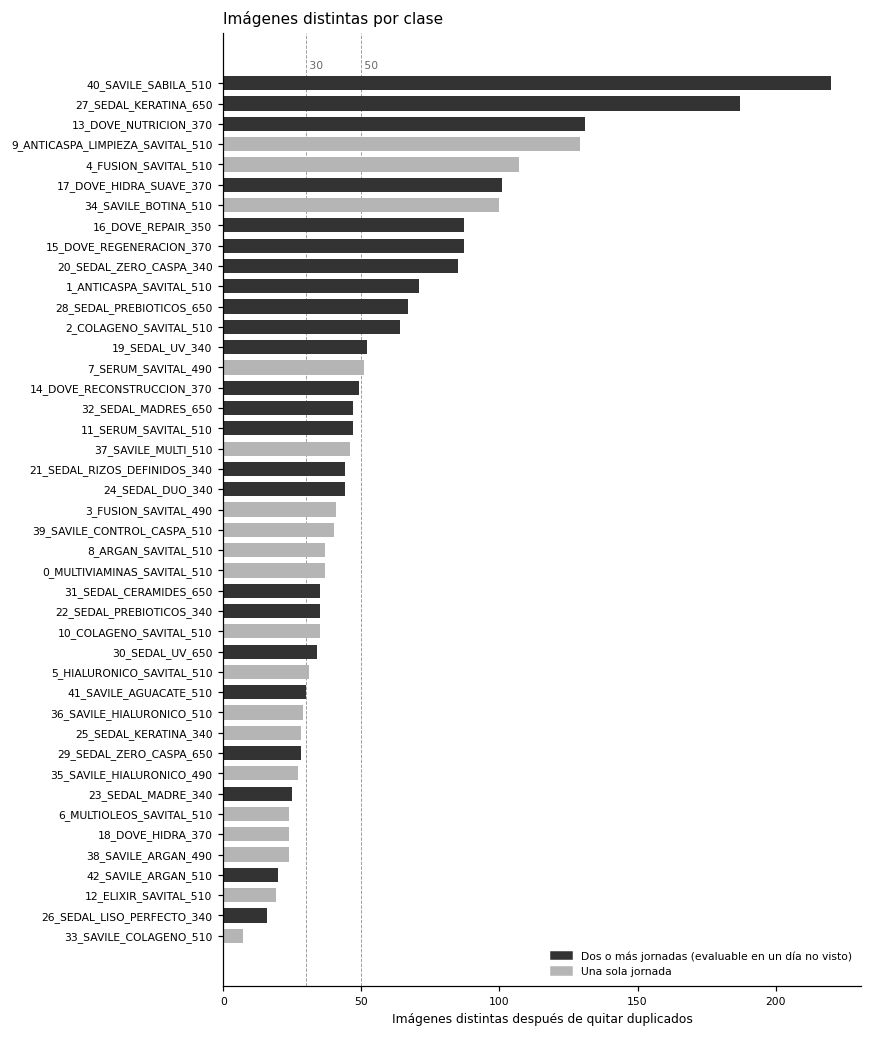

In [17]:
# ── Figura: imágenes distintas por clase ──
from matplotlib.patches import Patch

d = dist.sort_values('imagenes_distintas')
colores = np.where(d.evaluable_por_jornada, '#333333', '#b5b5b5')

fig, ax = plt.subplots(figsize=(8, 9.5))
ax.barh(d.index, d.imagenes_distintas, color=colores, height=0.7)
for x in (30, 50):
    ax.axvline(x, color='#999999', linewidth=0.6, linestyle='--', zorder=0)
    ax.text(x, len(d) - 0.4, f' {x}', fontsize=7, color='#666666', va='bottom')
ax.tick_params(axis='y', labelsize=7)
ax.tick_params(axis='x', labelsize=7)
ax.set_xlabel('Imágenes distintas después de quitar duplicados', fontsize=8)
for borde in ('top', 'right'):
    ax.spines[borde].set_visible(False)
ax.legend(handles=[Patch(color='#333333', label='Dos o más jornadas (evaluable en un día no visto)'),
                   Patch(color='#b5b5b5', label='Una sola jornada')],
          loc='lower right', frameon=False, fontsize=7)
ax.set_title('Imágenes distintas por clase', fontsize=10, loc='left')
plt.tight_layout()
plt.savefig(SALIDA / 'fig_distribucion_clases.png', dpi=200, bbox_inches='tight')
plt.show()

#### Lectura de resultados: imágenes distintas por clase

Cada barra es una clase, ordenada por número de imágenes distintas. El tono oscuro
indica que la clase tiene dos o más jornadas y puede evaluarse en un día no visto; el
gris claro, que tiene una sola. Las líneas punteadas marcan 30 y 50 imágenes.

Los dos tonos aparecen a lo largo de toda la escala, desde las clases de menos de 30
imágenes hasta las de más de 100. Tener muchas imágenes no garantiza que una clase
pueda evaluarse con rigor: lo que lo permite es haberla capturado en más de un día.

Para los pares que solo difieren en el contenido neto, el panorama es este. En el
par Fusión, ni la carpeta 3 (490) ni la 4 (510) son evaluables por jornada. En el par
Sérum, la carpeta 11 (510) sí lo es, con tres jornadas, pero la 7 (490) no. Con el
conjunto actual no hay forma de medir, en días no vistos, si el modelo distingue 490
de 510.